# A/B-тест новой платёжной воронки

**Заказчик:** крупный интернет-магазин, работающий преимущественно в Азии.
**Тест:** `new_payment_funnel_test_summer_2025`.
**Гипотеза заказчика:** новая платёжная воронка (группа B) увеличит конверсию в покупку по сравнению с текущей (группа A).

Сейчас 21 июня 2025 года, тест завершён. Нужно проверить, корректно ли он проведён, и решить, внедрять ли новую воронку.

**План работы**
1. Загрузка и подготовка данных.
2. Проверка корректности теста: сроки, состав участников, распределение по группам.
3. Исследовательский анализ: конверсия и кумулятивная динамика метрик.
4. Проверка гипотез.
5. Выводы и рекомендации.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as st

# Функции подготовки и статистические тесты лежат в src/abtest.py
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT / "src"))
import abtest as ab

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
ALPHA = 0.05

# Единый стиль графиков; группа A — синий, B — оранжевый
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COLORS = {"A": "#2a78d6", "B": "#eb6834"}
LABELS = {"A": "A — текущая воронка", "B": "B — новая воронка"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "font.size": 11, "legend.frameon": False,
})


def fmt_p(p):
    # p-value в читаемом виде: очень маленькие значения не округляются до «0.000»
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def date_axis(ax):
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))

## Шаг 1. Загрузка и подготовка данных

| Файл | Содержание |
|---|---|
| `new_users_test_2025.csv` | новые пользователи: дата регистрации, регион, устройство |
| `sessions_test_2025.csv` | сессии новых пользователей: начало и длительность в минутах |
| `purchases_test_2025.csv` | покупки новых пользователей: дата и время, сумма в долларах |
| `participants_test_2025.csv` | участники тестов: группа и название теста |

In [2]:
raw = ab.load_raw(ROOT / "data" / "raw")
users, sessions, purchases, participants = (raw[k] for k in ["users", "sessions", "purchases", "participants"])

overview = pd.DataFrame({
    name: {
        "строк": len(df),
        "пропусков": int(df.isna().sum().sum()),
        "полных дубликатов": int(df.duplicated().sum()),
    }
    for name, df in raw.items()
}).T
overview

,строк,пропусков,полных дубликатов
users,131486,0,0
sessions,491443,0,0
purchases,149152,0,0
participants,3291,0,0


In [3]:
# Какие периоды на самом деле покрывают данные
pd.DataFrame({
    "с": [users["first_date"].min(), sessions["session_start"].min(), purchases["event_dt"].min()],
    "по": [users["first_date"].max(), sessions["session_start"].max(), purchases["event_dt"].max()],
}, index=["регистрации", "сессии", "покупки"])

,с,по
регистрации,2025-06-01 00:00:00,2025-06-30 00:00:00
сессии,2025-06-01 00:00:17,2025-07-14 23:59:22
покупки,2025-06-01 00:00:17,2025-07-14 23:53:06


In [4]:
print("Повторяющихся user_id среди новых пользователей:", users["user_id"].duplicated().sum())
print("Отрицательная длительность сессии:", (sessions["session_duration"] < 0).sum())
print("Покупки с суммой ≤ 0:", (purchases["revenue"] <= 0).sum())
purchases["revenue"].value_counts().head(6).rename("покупок").to_frame()

Повторяющихся user_id среди новых пользователей: 0
Отрицательная длительность сессии: 0
Покупки с суммой ≤ 0: 0


,покупок
revenue,
4.990,110217
9.990,22497
99.990,13541
499.990,2897


Пропусков и дубликатов нет, даты при загрузке сразу переведены в `datetime`, некорректных значений нет.
Покупки идут по фиксированным ценам (4,99, 9,99, …, 499,99 $) — это похоже на пакеты внутриигровой
валюты или подписки.

**Важно:** данные выходят за рамки теста. Регистрации идут до 30 июня, а сессии и покупки — до 14 июля.
По условию тест закончился 21 июня, поэтому дальше учитываем только регистрации 1–14 июня
и события до конца 21 июня. Если этого не сделать, выручка группы искусственно вырастет за счёт покупок
после окончания теста.

## Шаг 2. Корректность проведения теста

### 2.1. Участники и пересечения с другим тестом

In [5]:
participants.groupby(["ab_test", "group"])["user_id"].nunique().unstack().rename_axis(columns=None)

,A,B
ab_test,,
new_login_screen_apac,107,118
new_payment_funnel_test_summer_2025,1598,1468


In [6]:
test = participants[participants["ab_test"] == ab.TEST_NAME]
other = participants[participants["ab_test"] != ab.TEST_NAME]

print("Пользователей в обеих группах нашего теста:", int((test.groupby("user_id")["group"].nunique() > 1).sum()))
print("Пользователей одновременно в другом тесте:", len(set(test["user_id"]) & set(other["user_id"])))

members = ab.test_users(users, participants)
print(f"Участников нашли в таблице регистраций: {len(members)} из {len(test)}")
print("Даты регистрации участников:", members["first_date"].min().date(), "—", members["first_date"].max().date())

Пользователей в обеих группах нашего теста: 0
Пользователей одновременно в другом тесте: 0
Участников нашли в таблице регистраций: 3066 из 3066
Даты регистрации участников: 2025-06-01 — 2025-06-14


Пересечений нет: ни один пользователь не попал сразу в обе группы и не участвовал в параллельном тесте
`new_login_screen_apac`. Все участники зарегистрировались в период набора — с 1 по 14 июня.

### 2.2. Аудитория теста

In [7]:
in_window = users[users["first_date"] <= ab.REGISTRATION_END]
audience = pd.DataFrame({
    "участников": members["region"].value_counts(),
    "новых пользователей 1–14 июня": in_window["region"].value_counts(),
})
audience["доля участников"] = audience["участников"] / audience["участников"].sum()
audience["охват региона"] = audience["участников"] / audience["новых пользователей 1–14 июня"]
audience.sort_values("участников", ascending=False)

,участников,новых пользователей 1–14 июня,доля участников,охват региона
region,,,,
Southeast Asia,2951,26829,0.962,0.110
Central Asia,47,14868,0.015,0.003
East Asia,42,8926,0.014,0.005
South Asia,26,8928,0.008,0.003


Тест фактически нацелен на **Юго-Восточную Азию**: 96% участников оттуда, и в тест попал примерно каждый
девятый новый пользователь этого региона. Из других регионов в тест попало всего около 100 человек
(доля меньше 0,5% их новых пользователей). Похоже, что это «утечка» из другой аудитории, а не часть плана.
На результат она почти не влияет, но это отклонение от ожидаемой аудитории, и его стоит передать заказчику.

### 2.3. Распределение по группам (SRM)

Если трафик делили 50/50, группы должны быть примерно равны. Проверим это хи-квадрат тестом
на **Sample Ratio Mismatch** — несоответствие размеров групп плановому соотношению.

In [8]:
group_sizes = members["group"].value_counts().sort_index()
srm_p = ab.srm_test(group_sizes)
print(f"A: {group_sizes['A']}, B: {group_sizes['B']} — доля A {group_sizes['A'] / group_sizes.sum():.1%}")
print(f"SRM-тест: p-value = {fmt_p(srm_p)}")

A: 1598, B: 1468 — доля A 52.1%
SRM-тест: p-value = 0.019


In [9]:
# Сбалансированы ли группы по составу
balance = {}
for col in ["device", "region"]:
    table = pd.crosstab(members[col], members["group"])
    balance[col] = st.chi2_contingency(table).pvalue
    display(pd.crosstab(members[col], members["group"], normalize="columns").style.format("{:.1%}"))
print({k: fmt_p(v) for k, v in balance.items()})

{'device': '0.089', 'region': '0.498'}


group,A,B
device,,
Android,44.9%,43.7%
Mac,8.4%,11.2%
PC,26.5%,25.3%
iPhone,20.2%,19.8%


group,A,B
region,,
Central Asia,1.8%,1.3%
East Asia,1.6%,1.2%
South Asia,0.8%,1.0%
Southeast Asia,95.9%,96.6%


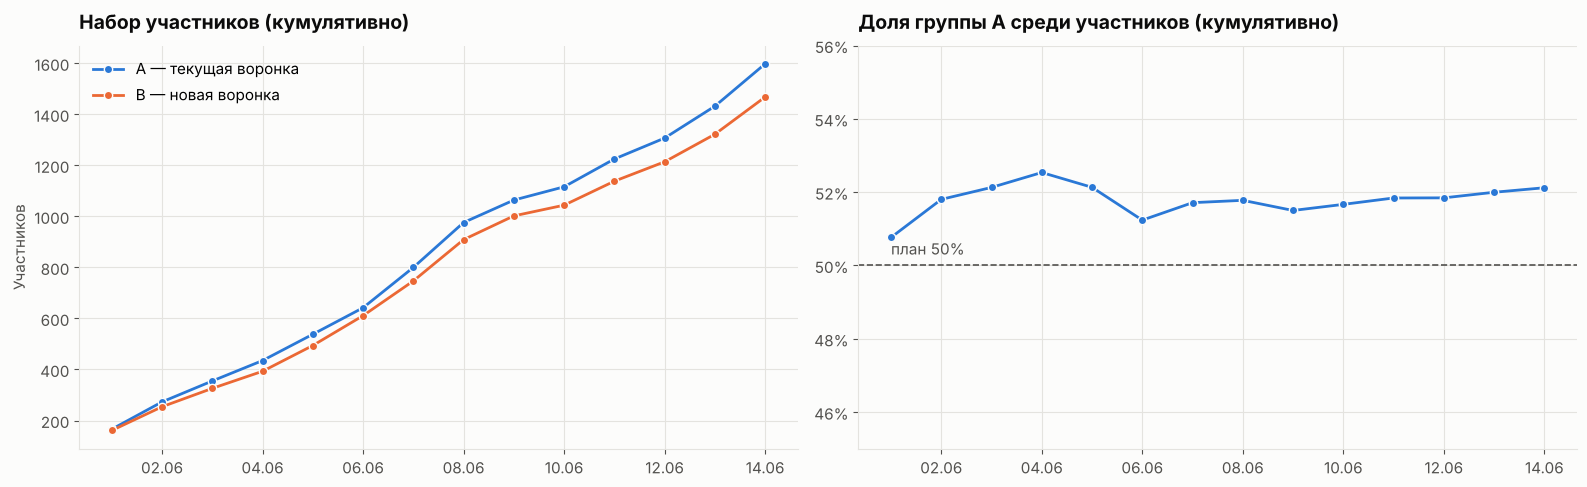

In [10]:
# Как шёл набор: доля группы A среди участников по дням
daily = members.groupby(["first_date", "group"]).size().unstack()
cum_share_a = daily["A"].cumsum() / daily.sum(axis=1).cumsum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
for g in ["A", "B"]:
    ax1.plot(daily.index, daily[g].cumsum(), color=COLORS[g], marker="o", markersize=6,
             markeredgecolor=SURFACE, linewidth=2, label=LABELS[g])
ax1.set_title("Набор участников (кумулятивно)")
ax1.set_ylabel("Участников")
ax1.legend()
date_axis(ax1)

ax2.plot(cum_share_a.index, cum_share_a, color=COLORS["A"], marker="o", markersize=6, markeredgecolor=SURFACE, linewidth=2)
ax2.axhline(0.5, color=INK_MUTED, linestyle="--", linewidth=1.2)
ax2.text(cum_share_a.index[0], 0.502, "план 50%", color=INK_MUTED, va="bottom")
ax2.set_ylim(0.45, 0.56)
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.set_title("Доля группы A среди участников (кумулятивно)")
date_axis(ax2)

fig.tight_layout()
fig.savefig(FIG_DIR / "01_enrollment.png", dpi=150, bbox_inches="tight")
plt.show()

**Здесь главная проблема теста.** В группе A на 130 человек больше (52,1% против 47,9%), и SRM-тест показывает
p ≈ 0.02: при честном делении 50/50 такой перекос случайно возникает лишь в 2% случаев. Доля A выше 50%
почти весь период набора, то есть это систематический сдвиг, а не случайность одного дня.

По устройствам и регионам группы различаются незначимо, хотя в B заметно больше пользователей Mac
(11,2% против 8,4%). SRM означает, что механизм распределения или логирования мог работать с ошибкой.
Например, часть пользователей B могла не попасть в данные, если новая воронка у них не загрузилась.
Поэтому результаты теста нужно интерпретировать осторожно.

## Шаг 3. Исследовательский анализ

### 3.1. Конверсия в покупку

In [11]:
buys = ab.within_test(purchases, "event_dt", members)
sess = ab.within_test(sessions, "session_start", members)
print(f"Покупок после окончания теста отброшено: {len(purchases.merge(members[['user_id']], on='user_id')) - len(buys)}")

# Метрики на пользователя
members["buyer"] = members["user_id"].isin(buys["user_id"])
members["revenue"] = members["user_id"].map(buys.groupby("user_id")["revenue"].sum()).fillna(0)
members["purchases"] = members["user_id"].map(buys.groupby("user_id").size()).fillna(0)

metrics = members.groupby("group").agg(
    участников=("user_id", "size"),
    покупателей=("buyer", "sum"),
    конверсия=("buyer", "mean"),
    выручка_на_участника=("revenue", "mean"),
)
metrics["выручка_на_покупателя"] = members[members["buyer"]].groupby("group")["revenue"].mean()
metrics["покупок_на_покупателя"] = members[members["buyer"]].groupby("group")["purchases"].mean()
metrics.T

Покупок после окончания теста отброшено: 296


group,A,B
участников,"1,598.000","1,468.000"
покупателей,472.000,270.000
конверсия,0.295,0.184
выручка_на_участника,23.689,13.758
выручка_на_покупателя,80.202,74.804
покупок_на_покупателя,3.104,2.981


In [12]:
# Когда совершается первая покупка
first_buy = buys.groupby("user_id").agg(first=("event_dt", "min"), reg=("first_date", "first"))
(first_buy["first"].dt.normalize() - first_buy["reg"]).dt.days.value_counts().rename("покупателей").rename_axis("дней после регистрации").to_frame()

,покупателей
дней после регистрации,
0,742


**Конверсия в группе B — 18,4% против 29,5% в A**, то есть новая воронка снизила её примерно на треть.
Выручка на участника в B тоже ниже, а вот покупатели в обеих группах тратят и покупают примерно одинаково.
Все первые покупки совершаются **в день регистрации**. Значит, платёжная воронка — часть онбординга:
либо пользователь платит сразу, либо уже не возвращается к оплате.

### 3.2. Кумулятивная динамика метрик

Накапливаем метрики по дням: на каждую дату — все участники, зарегистрированные к этому дню, и все их покупки.
Так видно, стабилизировалась ли разница или колебалась в ходе теста.

In [13]:
dates = pd.date_range(ab.REGISTRATION_START, ab.TEST_END - pd.Timedelta(days=1))
rows = []
for d in dates:
    m = members[members["first_date"] <= d]
    b = buys[buys["event_dt"] < d + pd.Timedelta(days=1)]
    for g in ["A", "B"]:
        mg, bg = m[m["group"] == g], b[b["group"] == g]
        rows.append({
            "date": d, "group": g, "участников": len(mg), "покупок": len(bg),
            "конверсия": bg["user_id"].nunique() / len(mg), "выручка": bg["revenue"].sum(),
            "сессий": int((sess[(sess["group"] == g) & (sess["session_start"] < d + pd.Timedelta(days=1))]).shape[0]),
        })
cum = pd.DataFrame(rows)
cum["выручка_на_участника"] = cum["выручка"] / cum["участников"]
cum_wide = cum.pivot(index="date", columns="group")
cum_wide.tail(1).T.unstack()

date                 2025-06-21           
group                         A          B
участников            1,598.000  1,468.000
покупок               1,465.000    805.000
конверсия                 0.295      0.184
выручка              37,855.350 20,196.950
сессий                5,095.000  4,825.000
выручка_на_участника     23.689     13.758

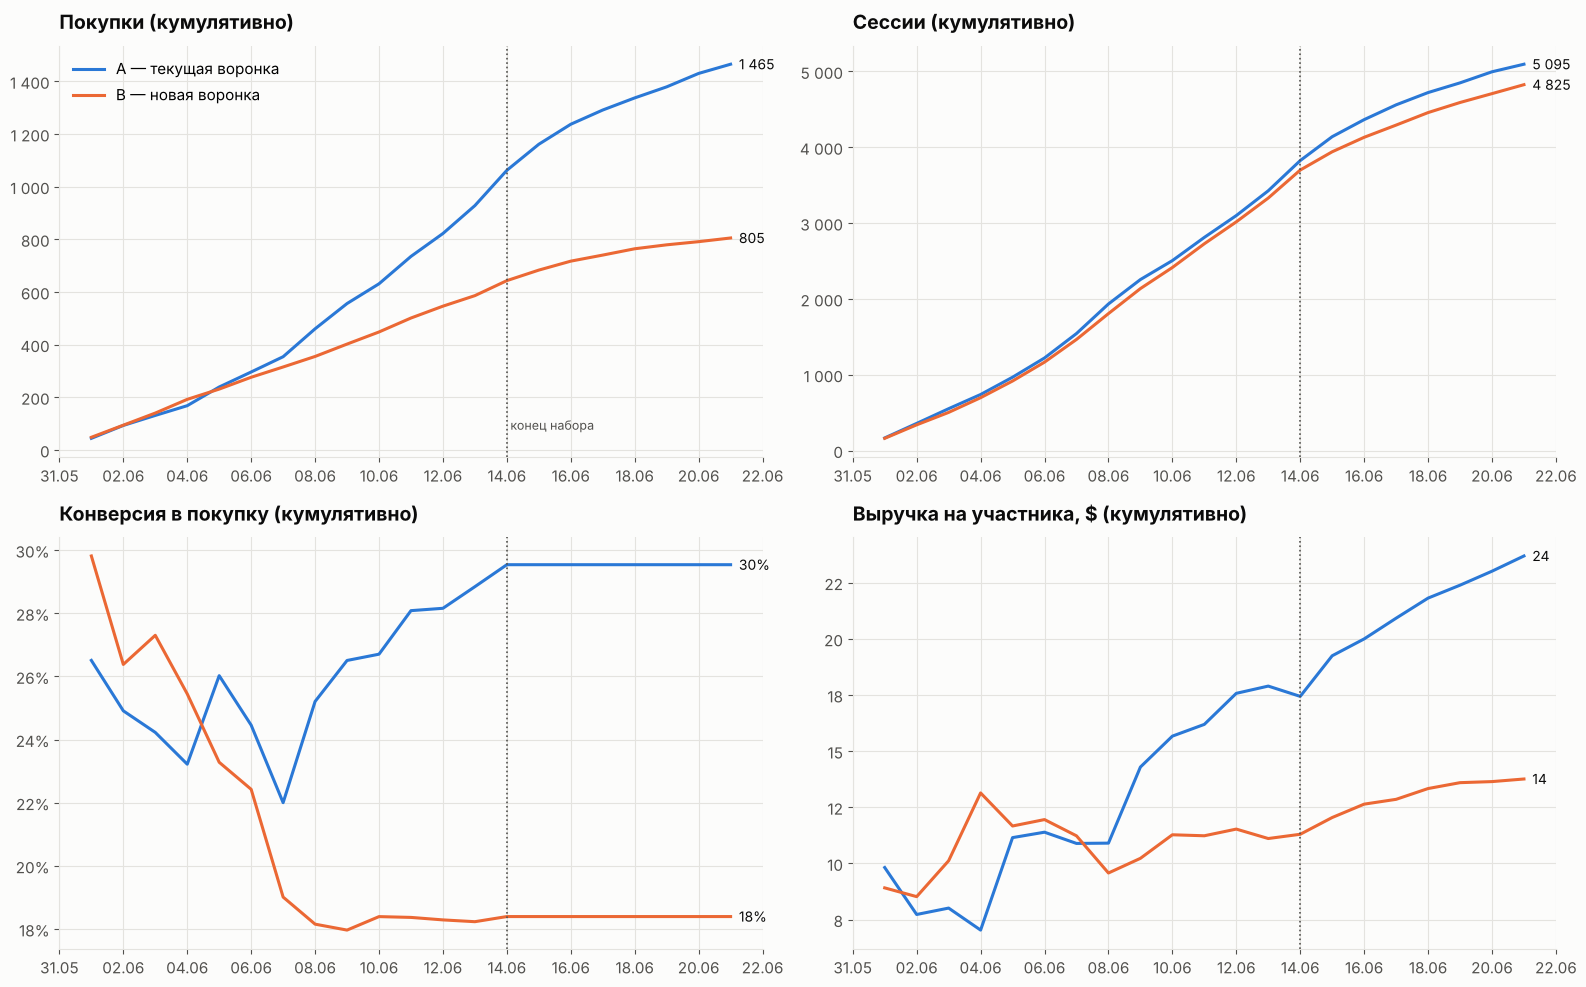

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
panels = [
    ("покупок", "Покупки", "{:,.0f}"),
    ("сессий", "Сессии", "{:,.0f}"),
    ("конверсия", "Конверсия в покупку", "{:.0%}"),
    ("выручка_на_участника", "Выручка на участника, $", "{:.0f}"),
]
for ax, (col, title, fmt) in zip(axes.flat, panels):
    for g in ["A", "B"]:
        ax.plot(cum_wide.index, cum_wide[(col, g)], color=COLORS[g], linewidth=2.2, label=LABELS[g])
        ax.annotate(fmt.format(cum_wide[(col, g)].iloc[-1]).replace(",", " "),
                    (cum_wide.index[-1], cum_wide[(col, g)].iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", color=INK, fontsize=10)
    ax.axvline(ab.REGISTRATION_END, color=INK_MUTED, linestyle=":", linewidth=1.2)
    ax.set_title(f"{title} (кумулятивно)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, f=fmt: f.format(v).replace(",", " ")))
    date_axis(ax)
axes[0, 0].legend(loc="upper left")
axes[0, 0].text(ab.REGISTRATION_END, axes[0, 0].get_ylim()[1] * 0.05, " конец набора", color=INK_MUTED, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_cumulative_metrics.png", dpi=150, bbox_inches="tight")
plt.show()

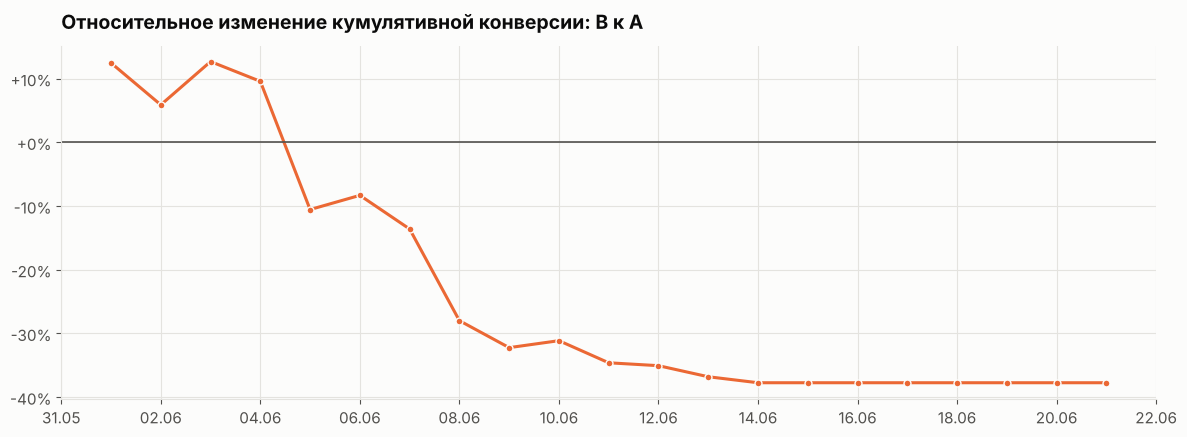

In [15]:
# Относительная разница кумулятивной конверсии B к A
rel = cum_wide[("конверсия", "B")] / cum_wide[("конверсия", "A")] - 1

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(rel.index, rel, color=COLORS["B"], linewidth=2.2, marker="o", markersize=5, markeredgecolor=SURFACE)
ax.axhline(0, color=INK_MUTED, linewidth=1.2)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.set_title("Относительное изменение кумулятивной конверсии: B к A")
date_axis(ax)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_relative_conversion.png", dpi=150, bbox_inches="tight")
plt.show()

**Наблюдения**

- **Покупки и выручка** у группы A накапливаются быстрее с первых дней теста, разрыв растёт всё время набора.
  После 14 июня новых участников нет, и рост почти останавливается: все покупки совершаются в день регистрации.
- **Сессий** у групп примерно поровну с поправкой на размер: пользователи B заходят на сайт не реже.
  Проблема не в вовлечённости, а именно в оплате.
- **Конверсия ведёт себя неожиданно.** В первые дни B даже немного впереди, но около 6–7 июня её конверсия
  резко проседает, и после этого относительная разница держится на уровне около −38%. Проверим, есть ли
  здесь перелом, сравнив пользователей, зарегистрированных до и после 6 июня.

In [16]:
members["период"] = np.where(members["first_date"] < "2025-06-06", "1–5 июня", "6–14 июня")
period = members.groupby(["период", "group"])["buyer"].agg(конверсия="mean", покупателей="sum", участников="size")
tests = {}
for per in ["1–5 июня", "6–14 июня"]:
    part = period.loc[per]
    tests[per] = fmt_p(ab.proportions_ztest(part["покупателей"], part["участников"])[1])
display(period.unstack("group")["конверсия"].assign(**{"p-value": pd.Series(tests)}))

# Конверсия группы B по устройствам до и после перелома
members[members["group"] == "B"].groupby(["период", "device"])["buyer"].mean().unstack().style.format("{:.0%}")

group,A,B,p-value
период,,,
1–5 июня,0.260,0.233,0.307
6–14 июня,0.313,0.159,< 0.001


device,Android,Mac,PC,iPhone
период,,,,
1–5 июня,23%,20%,24%,26%
6–14 июня,19%,15%,12%,15%


**Перелом есть.** У пользователей, пришедших 1–5 июня, конверсия в группах почти одинакова (26% против 23%),
и разница статистически незначима (p ≈ 0.3). У пришедших с 6 июня разрыв огромный: 31% против 16%.
Конверсия B после 6 июня упала на всех устройствах, сильнее всего — на PC и iPhone.

Похоже, что примерно 6 июня в новой воронке что-то изменилось: вышел релиз с ошибкой, поменялся
платёжный провайдер или включился новый шаг оплаты. Это нужно сверить с журналом релизов.
Возможно, сама по себе новая воронка не хуже старой, а результат испортил сбой в середине теста.

### 3.3. Где теряет новая воронка

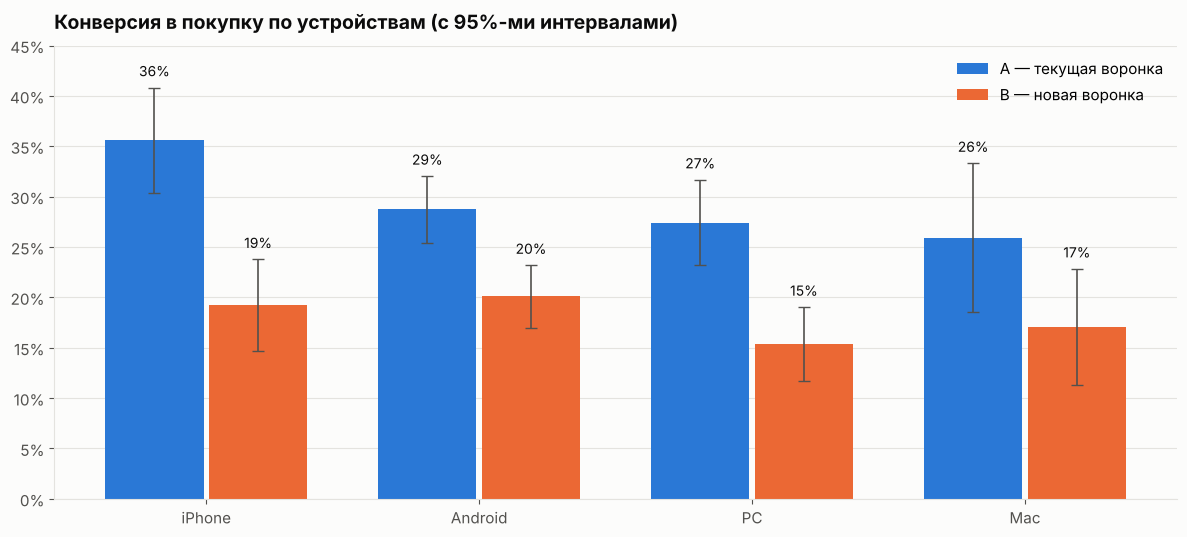

mean       size     
group       A     B    A    B
device                       
iPhone  0.356 0.192  323  291
Android 0.287 0.201  717  642
PC      0.274 0.154  423  371
Mac     0.259 0.171  135  164

In [17]:
def prop_ci(s):
    # 95%-й интервал для доли (нормальное приближение)
    p, n = s.mean(), len(s)
    return 1.96 * np.sqrt(p * (1 - p) / n)

by_device = members.groupby(["device", "group"])["buyer"].agg(["mean", "size", prop_ci]).unstack()
order = by_device[("mean", "A")].sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(order))
for i, g in enumerate(["A", "B"]):
    vals = by_device.loc[order, ("mean", g)]
    err = by_device.loc[order, ("prop_ci", g)]
    bars = ax.bar(x + (i - 0.5) * 0.38, vals, width=0.36, color=COLORS[g], label=LABELS[g],
                  yerr=err, error_kw={"ecolor": INK_MUTED, "elinewidth": 1.2, "capsize": 4})
    for xi, v, e in zip(x + (i - 0.5) * 0.38, vals, err):
        ax.text(xi, v + e + 0.008, f"{v:.0%}", ha="center", va="bottom", color=INK, fontsize=10)
ax.set_xticks(x, order)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, 0.45)
ax.set_title("Конверсия в покупку по устройствам (с 95%-ми интервалами)")
ax.grid(axis="x", visible=False)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "04_conversion_by_device.png", dpi=150, bbox_inches="tight")
plt.show()

by_device.loc[order, ["mean", "size"]]

       mean  median
group              
A     2.130   2.000
B     3.590   3.480
Манн — Уитни: < 0.001


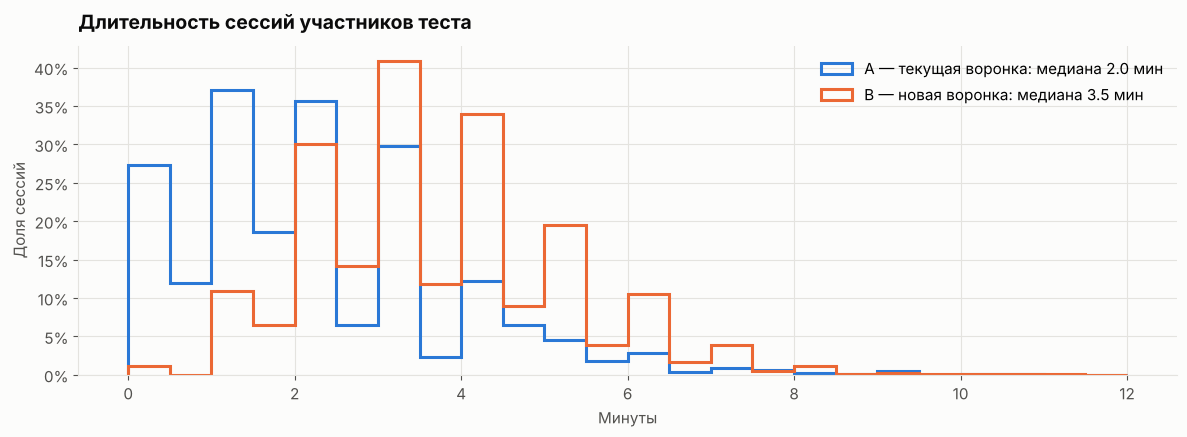

In [18]:
# Длительность сессий: что происходит внутри воронки
dur = sess.groupby("group")["session_duration"]
print(dur.agg(["mean", "median"]).round(2).to_string())
print("Манн — Уитни:", fmt_p(st.mannwhitneyu(sess.loc[sess["group"] == "A", "session_duration"],
                                             sess.loc[sess["group"] == "B", "session_duration"]).pvalue))

fig, ax = plt.subplots(figsize=(12, 4.5))
bins = np.arange(0, 12.5, 0.5)
for g in ["A", "B"]:
    ax.hist(sess.loc[sess["group"] == g, "session_duration"], bins=bins, density=True, histtype="step",
            linewidth=2.2, color=COLORS[g], label=f"{LABELS[g]}: медиана {dur.median()[g]:.1f} мин")
ax.set_title("Длительность сессий участников теста")
ax.set_xlabel("Минуты")
ax.set_ylabel("Доля сессий")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "05_session_duration.png", dpi=150, bbox_inches="tight")
plt.show()

**Наблюдения**

- Новая воронка проигрывает **на всех устройствах**; интервалы пересекаются только у Mac, где мало пользователей.
  Сильнее всего падение на iPhone и PC. Проблема не привязана к одной платформе.
- **Сессии в группе B заметно длиннее.** Пользователи проводят больше времени, но покупают реже.
  Это типичный признак трения: новая воронка сложнее, пользователь дольше в ней разбирается и чаще бросает оплату.

## Шаг 4. Проверка гипотез

**Основная метрика — конверсия в покупку** (доля участников с хотя бы одной покупкой).

- **H₀:** конверсия в группах A и B одинакова.
- **H₁:** конверсия различается (двусторонняя гипотеза).

Конверсия — доля, группы независимы и большие (по ~1,5 тыс.), поэтому подходит **z-тест для двух пропорций**.
Двусторонняя гипотеза выбрана сознательно: новая воронка может как улучшить, так и ухудшить конверсию,
и ухудшение тоже нужно обнаружить.

In [19]:
succ = members.groupby("group")["buyer"].sum()
tot = members.groupby("group").size()
z, p_conv = ab.proportions_ztest(succ, tot)
low, high = ab.diff_ci(succ, tot)
conv = succ / tot

print(f"Конверсия: A {conv['A']:.1%}, B {conv['B']:.1%}")
print(f"Разница B − A: {(conv['B'] - conv['A']) * 100:+.1f} п.п. (95% ДИ: {low * 100:+.1f} … {high * 100:+.1f} п.п.)")
print(f"Относительное изменение: {conv['B'] / conv['A'] - 1:+.0%}")
print(f"z = {z:.2f}, p-value {fmt_p(p_conv)}")
print("Отвергаем H₀" if p_conv < ALPHA else "Не удалось отвергнуть H₀")

Конверсия: A 29.5%, B 18.4%
Разница B − A: -11.1 п.п. (95% ДИ: -14.1 … -8.2 п.п.)
Относительное изменение: -38%
z = -7.20, p-value < 0.001
Отвергаем H₀


**Дополнительные метрики**

Выручка сильно скошена (большинство покупок по 4,99 $, единицы — по 499,99 $), поэтому для неё используем
критерий Манна — Уитни и бутстреп-интервал разности средних, а не t-тест.

In [20]:
rev_a = members.loc[members["group"] == "A", "revenue"].values
rev_b = members.loc[members["group"] == "B", "revenue"].values
buy_a = members.loc[(members["group"] == "A") & members["buyer"], "revenue"].values
buy_b = members.loc[(members["group"] == "B") & members["buyer"], "revenue"].values

extra = pd.DataFrame([
    {"метрика": "Выручка на участника, $", "A": rev_a.mean(), "B": rev_b.mean(),
     "95% ДИ разницы (бутстреп)": "{:+.2f} … {:+.2f}".format(*ab.bootstrap_mean_diff(rev_a, rev_b)),
     "p-value (Манн — Уитни)": fmt_p(st.mannwhitneyu(rev_a, rev_b).pvalue)},
    {"метрика": "Выручка на покупателя, $", "A": buy_a.mean(), "B": buy_b.mean(),
     "95% ДИ разницы (бутстреп)": "{:+.2f} … {:+.2f}".format(*ab.bootstrap_mean_diff(buy_a, buy_b)),
     "p-value (Манн — Уитни)": fmt_p(st.mannwhitneyu(buy_a, buy_b).pvalue)},
]).set_index("метрика")
extra

,A,B,95% ДИ разницы (бутстреп),p-value (Манн — Уитни)
метрика,,,,
"Выручка на участника, $",23.689,13.758,-15.10 … -4.96,< 0.001
"Выручка на покупателя, $",80.202,74.804,-25.27 … +14.95,0.346


In [21]:
# Устойчивость вывода к SRM: даже если бы в B «потерялись» пользователи, это не спасает новую воронку.
# Предположим худшее для A: недостающие до 50/50 пользователи B (≈65 человек) все были покупателями.
missing = (tot.sum() // 2) - tot["B"]
succ_adj, tot_adj = succ.copy(), tot.copy()
succ_adj["B"] += missing
tot_adj["B"] += missing
_, p_adj = ab.proportions_ztest(succ_adj, tot_adj)
print(f"Добавили в B {missing} «покупателей»: конверсия B {succ_adj['B'] / tot_adj['B']:.1%} против A {conv['A']:.1%}, p-value {fmt_p(p_adj)}")

Добавили в B 65 «покупателей»: конверсия B 21.9% против A 29.5%, p-value < 0.001


**Результаты**

- **Конверсия:** H₀ отвергаем, p < 0.001. Новая воронка **снижает** конверсию с 29,5% до 18,4% —
  на 11 п.п. (95% ДИ: от −14 до −8 п.п.), или примерно на 38%. Гипотеза заказчика о росте конверсии не подтвердилась:
  эффект статистически значим, но в обратную сторону.
- **Выручка на участника** в B ниже примерно на 40%, различие значимо.
- **Выручка на покупателя** значимо не различается: те, кто дошёл до оплаты, тратят одинаково.
  Новая воронка не меняет чек, она отсекает часть покупателей.
- **SRM не меняет вывод.** Даже в заведомо худшем для A сценарии — если бы все «недостающие» пользователи B
  оказались покупателями — конверсия B осталась бы значимо ниже.

## Шаг 5. Выводы и рекомендации

**Был ли тест проведён согласно заданию?** В основном да, с отклонениями:
- сроки соблюдены: набор 1–14 июня, наблюдение до 21 июня; события после окончания теста исключены из анализа;
- пересечений с параллельным тестом и между группами нет;
- в тест попало около 100 пользователей не из Юго-Восточной Азии, на которую он фактически нацелен, — небольшая утечка аудитории.

**Было ли распределение на группы корректным?** Не полностью. Группы различаются по размеру сильнее,
чем допускает случайность (SRM, p ≈ 0.02), и перекос держался весь период набора. По устройствам
и регионам группы сбалансированы. Перекос нужно расследовать, но на итоговый вывод он не влияет:
разница в конверсии устойчива даже в худшем сценарии.

**Есть ли различие в целевой метрике?** Да. Новая платёжная воронка **снижает конверсию в покупку
примерно на треть** (29,5% → 18,4%), и вместе с ней на ~40% падает выручка на пользователя.
Средний чек покупателя не меняется. Но разница возникла не сразу: в первые 5 дней группы шли наравне,
а разрыв появился у пользователей, пришедших с 6 июня, — на всех устройствах сразу.

**Рекомендации заказчику**
1. **Не внедрять новую воронку в текущем виде.** По итогам теста она ухудшает основную метрику,
   и при раскатке на всех магазин потерял бы около трети новых покупателей.
2. **Выяснить, что случилось около 6 июня.** До этой даты группы шли наравне. Если причина — технический сбой
   (релиз, платёжный провайдер), его нужно исправить и **перезапустить тест**: возможно, исправленная
   воронка окажется не хуже старой.
3. **Найти, где ломается воронка.** Сессии в группе B заметно длиннее при меньшей конверсии — пользователи
   застревают в оплате. Нужна пошаговая аналитика воронки (событие на каждом шаге оплаты),
   чтобы найти шаг с наибольшим оттоком; в текущих данных шагов нет.
4. **Проверить систему распределения трафика.** До следующего теста стоит выяснить причину SRM:
   ошибка сплиттера, потеря событий в B или фильтрация ботов. Иначе следующие тесты тоже будут под сомнением.
5. **Задавать ожидаемую аудиторию явно** и проверять её на старте: тест на Юго-Восточную Азию
   не должен включать пользователей других регионов.